# Análisis de sentimiento de reseñas con redes recurrentes (LSTM vs GRU)

**Objetivo:** clasificar reseñas de películas como *positivas* o *negativas* usando una red recurrente bidireccional, comparar LSTM contra GRU y dejar el modelo listo para una app Streamlit.

> **Colab:** activa la GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.

In [1]:
import os, sys, json, re
REPO_URL = "https://github.com/SantiagoPerdomo25/rnn-sentimiento"
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone {REPO_URL} repo
    %cd repo
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from src import data, model as model_lib, evaluate

tf.keras.utils.set_random_seed(data.SEED)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

fatal: destination path 'repo' already exists and is not an empty directory.
/content/repo
TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Selección y descripción del dataset

Se usa **IMDB Large Movie Review Dataset** (Maas et al., Stanford): **50.000 reseñas** de películas en inglés, perfectamente balanceadas (25.000 positivas y 25.000 negativas). Las reseñas con puntuación ≤ 4/10 son negativas y las ≥ 7/10 positivas; las neutras se excluyeron.

**Por qué este dataset:**
- Es un problema de **datos secuenciales** (texto): el orden de las palabras y el contexto importan ("not good" ≠ "good").
- Las reseñas son largas y variables, lo que justifica el uso de memoria (LSTM/GRU).
- Es un benchmark conocido, con tamaño suficiente para entrenar en Colab.

In [2]:
data_dir = data.download_dataset("data")
df = data.load_dataframe(data_dir)       # lee train + test originales y los junta (50.000)
print("Forma:", df.shape)
display(df.head())
display(df.groupby(["original_split", "sentimiento"]).size().unstack())

Descargando IMDB (~80 MB)...
Descomprimiendo (puede tardar 1-2 minutos)...
Forma: (50000, 4)


,text,label,original_split,sentimiento
0,Story of a man who has unnatural feelings for ...,0,train,negativo
1,Airport '77 starts as a brand new luxury 747 p...,0,train,negativo
2,This film lacked something I couldn't put my f...,0,train,negativo
3,"Sorry everyone,,, I know this is supposed to b...",0,train,negativo
4,When I was little my parents took me along to ...,0,train,negativo


sentimiento,negativo,positivo
original_split,,
test,12500,12500
train,12500,12500


## 2. Análisis exploratorio de los datos (EDA)

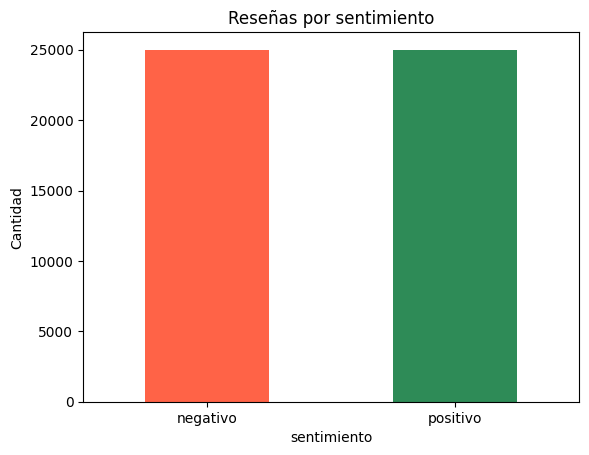

Nulos: 0 | Duplicados: 418


In [3]:
# Balance de clases
df["sentimiento"].value_counts().plot(kind="bar", color=["tomato", "seagreen"], rot=0,
                                      title="Reseñas por sentimiento")
plt.ylabel("Cantidad"); plt.show()
print("Nulos:", df["text"].isna().sum(), "| Duplicados:", df["text"].duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
sentimiento,,,,,,,,
negativo,25000.0,229.5,164.9,4.0,128.0,174.0,278.0,1522.0
positivo,25000.0,232.8,177.5,10.0,125.0,172.0,284.0,2470.0


Percentiles globales: {0.5: 173.0, 0.75: 280.0, 0.9: 451.0, 0.95: 590.0}


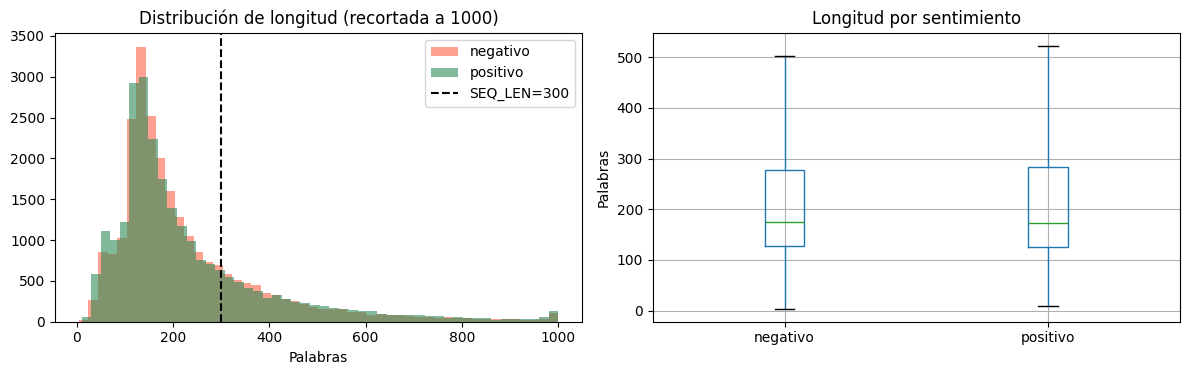

Con SEQ_LEN=300, el 78% de las reseñas cabe completo; el resto se recorta.


In [4]:
# Longitud de las reseñas (en palabras)
df["n_palabras"] = df["text"].str.split().str.len()
display(df.groupby("sentimiento")["n_palabras"].describe().round(1))
print("Percentiles globales:", df["n_palabras"].quantile([.5, .75, .9, .95]).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, c in zip(data.CLASS_NAMES, ["tomato", "seagreen"]):
    ax[0].hist(df.loc[df.sentimiento == s, "n_palabras"].clip(upper=1000), bins=50, alpha=.6, label=s, color=c)
ax[0].axvline(model_lib.SEQ_LEN, color="k", ls="--", label=f"SEQ_LEN={model_lib.SEQ_LEN}")
ax[0].set(title="Distribución de longitud (recortada a 1000)", xlabel="Palabras"); ax[0].legend()
df.boxplot(column="n_palabras", by="sentimiento", ax=ax[1], showfliers=False)
ax[1].set(title="Longitud por sentimiento", xlabel="", ylabel="Palabras"); plt.suptitle("")
plt.tight_layout(); plt.show()
cobertura = (df["n_palabras"] <= model_lib.SEQ_LEN).mean()
print(f"Con SEQ_LEN={model_lib.SEQ_LEN}, el {cobertura:.0%} de las reseñas cabe completo; el resto se recorta.")

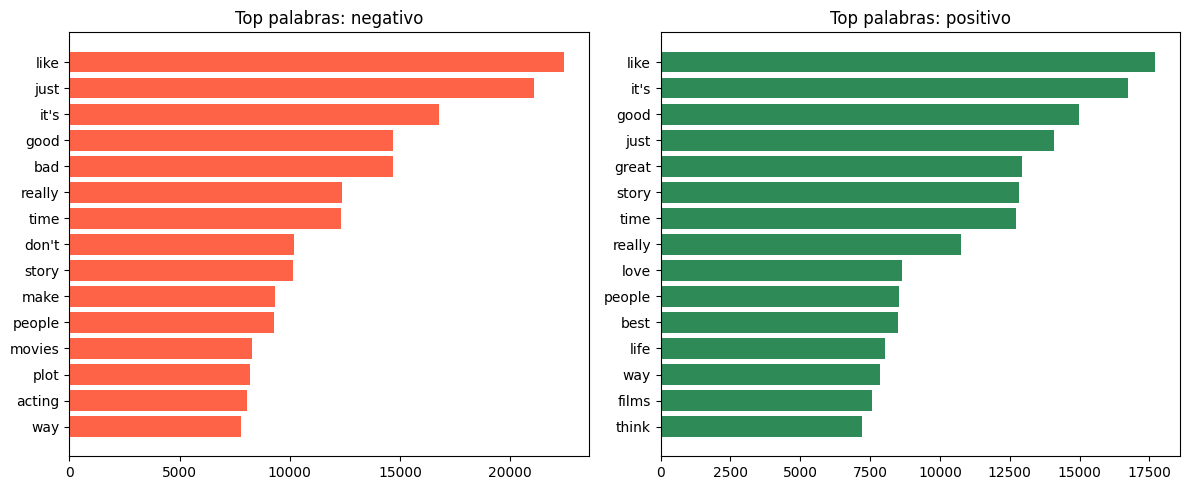

In [5]:
# Palabras más frecuentes por clase (sin stopwords)
stop = set(ENGLISH_STOP_WORDS) | {"br", "movie", "film", "s", "t"}
def top_words(texts, n=15):
    c = Counter(w for t in texts for w in re.findall(r"[a-z']+", t.lower()) if w not in stop and len(w) > 2)
    return c.most_common(n)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, s, col in zip(ax, data.CLASS_NAMES, ["tomato", "seagreen"]):
    words, counts = zip(*top_words(df.loc[df.sentimiento == s, "text"]))
    a.barh(words[::-1], counts[::-1], color=col); a.set_title(f"Top palabras: {s}")
plt.tight_layout(); plt.show()

In [6]:
# Ejemplos reales
for s in data.CLASS_NAMES:
    print(f"--- {s.upper()} ---")
    for t in df[df.sentimiento == s]["text"].sample(2, random_state=1):
        print("•", t[:300].replace("\n", " "), "...\n")

--- NEGATIVO ---
• A movie theater with a bad history of past gruesome murders reopens. Of course, the bloody killings start anew. Written, directed, shot, scored and edited with an appalling lack of flair and finesse by the singularly talentless Rick Sloane (who later disgraced celluloid some more with the absolutely ...

• What a long, drawn-out, pointless movie. I'm sure that historically this film is delightful but as entertainment goes it just doesn't make the grade. Ralph Fiennes has been in some fantastic movies, the English Patient, Schindler's List, but this one was such a let-down. It didn't seem to be going a ...

--- POSITIVO ---
• Sure, there's stuff here that the Coens and Elmore Leonard have done before, but so what? If you want entertaining, lusty and smart -- "Judas Kiss" is near perfect. Prudes offended by tongue in cheek porn don't get it (Talk about getting your sex and violence out of the way straight up -- keeps your ...

• After several extremely well ratings to 

## 3. Limpieza y preprocesamiento

1. **Duplicados:** se eliminan *antes* de dividir, para que una misma reseña no quede a la vez en entrenamiento y prueba (fuga de datos).
2. **Limpieza de texto:** se eliminan etiquetas HTML (`<br />`), URLs y espacios repetidos.
3. **Tokenización y vectorización:** una capa `TextVectorization` (minúsculas, sin puntuación) convierte cada reseña en una secuencia de **300 enteros** (vocabulario de 20.000 palabras; relleno o recorte según haga falta).
4. La capa va **dentro del modelo**, así la app Streamlit recibe texto crudo y no hay desajuste entre entrenamiento e inferencia.

In [7]:
ejemplo = df["text"].iloc[3]
print("ANTES:  ", ejemplo[:300])
print("DESPUÉS:", data.clean_text(ejemplo)[:300])

df = df.drop_duplicates(subset="text").reset_index(drop=True)
df["text_clean"] = df["text"].map(data.clean_text)
print("\nReseñas tras eliminar duplicados:", len(df))

ANTES:   Sorry everyone,,, I know this is supposed to be an "art" film,, but wow, they should have handed out guns at the screening so people could blow their brains out and not watch. Although the scene design and photographic direction was excellent, this story is too painful to watch. The absence of a sou
DESPUÉS: Sorry everyone,,, I know this is supposed to be an "art" film,, but wow, they should have handed out guns at the screening so people could blow their brains out and not watch. Although the scene design and photographic direction was excellent, this story is too painful to watch. The absence of a sou

Reseñas tras eliminar duplicados: 49582


## 4. División en entrenamiento, validación y prueba

División **estratificada 70 / 15 / 15** con semilla fija. El conjunto de prueba no se usa hasta la evaluación final.

In [8]:
splits = data.split_data(df)
display(pd.DataFrame({k: {"total": len(v), "positivas": int(v.label.sum()),
                          "negativas": int((1 - v.label).sum())} for k, v in splits.items()}).T)

ds = {k: data.make_dataset(v["text_clean"], v["label"], batch_size=64, training=(k == "train"))
      for k, v in splits.items()}

,total,positivas,negativas
train,34707,17419,17288
val,7437,3732,3705
test,7438,3733,3705


In [9]:
# El vocabulario se construye SOLO con entrenamiento (evita fuga de información)
vectorizer = model_lib.build_vectorizer(splits["train"]["text_clean"])
vocab = vectorizer.get_vocabulary()
print("Tamaño del vocabulario:", len(vocab), "| primeras palabras:", vocab[:15])

frase = "This movie was absolutely wonderful"
print("\nTexto:", frase)
print("Secuencia:", vectorizer([frase]).numpy()[0][:12], "...")

Tamaño del vocabulario: 20000 | primeras palabras: ['', '[UNK]', np.str_('the'), np.str_('a'), np.str_('and'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('was'), np.str_('as')]

Texto: This movie was absolutely wonderful
Secuencia: [ 11  17  13 410 387   0   0   0   0   0   0   0] ...


## 5. Construcción de la red neuronal

Arquitectura: *TextVectorization → Embedding(64, con máscara) → **Bidirectional(LSTM o GRU, 64)** → Dropout(0.5) → Dense(64) → Dropout(0.3) → Sigmoide*.

- **Embedding:** representa cada palabra como un vector denso aprendido.
- **Bidireccional:** lee la reseña de inicio a fin y de fin a inicio para captar contexto en ambos sentidos.
- **Dropout:** reduce el sobreajuste.
- Se entrenan **dos variantes (LSTM y GRU)** y se conserva la mejor según la validación.

In [10]:
model_lstm = model_lib.build_model(vectorizer, "lstm")
model_lstm.summary()

Model: "sentimiento_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ texto (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vectorizer          │ (None, 300)       │          0 │ texto[0][0]       │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 300, 64)   │  1,280,000 │ vectorizer[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 300)       │          0 │ vectorizer[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     66,048 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,354,369 (5.17 MB)

 Trainable params: 1,354,369 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento y comparación LSTM vs GRU

In [11]:
os.makedirs("models", exist_ok=True); os.makedirs("reports", exist_ok=True)
models, histories, rows = {}, {}, []
for cell in ["lstm", "gru"]:
    print(f"\n===== Entrenando {cell.upper()} =====")
    tf.keras.utils.set_random_seed(data.SEED)
    m = model_lib.build_model(vectorizer, cell)
    h = m.fit(ds["train"], validation_data=ds["val"], epochs=8, verbose=2,
              callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                                          restore_best_weights=True)])
    val_loss, val_acc, val_auc = m.evaluate(ds["val"], verbose=0)
    models[cell], histories[cell] = m, h
    rows.append({"modelo": cell.upper(), "épocas": len(h.history["loss"]), "val_loss": val_loss,
                 "val_accuracy": val_acc, "val_auc": val_auc})

comparacion = pd.DataFrame(rows).set_index("modelo").round(4)
display(comparacion)
best = comparacion["val_accuracy"].idxmax().lower()
model = models[best]
print("Mejor modelo en validación:", best.upper())


===== Entrenando LSTM =====
Epoch 1/8
543/543 - 23s - 43ms/step - accuracy: 0.8103 - auc: 0.8990 - loss: 0.4017 - val_accuracy: 0.8950 - val_auc: 0.9583 - val_loss: 0.2662
Epoch 2/8
543/543 - 17s - 30ms/step - accuracy: 0.9124 - auc: 0.9669 - loss: 0.2302 - val_accuracy: 0.8711 - val_auc: 0.9550 - val_loss: 0.3017
Epoch 3/8
543/543 - 16s - 30ms/step - accuracy: 0.9505 - auc: 0.9868 - loss: 0.1407 - val_accuracy: 0.8821 - val_auc: 0.9508 - val_loss: 0.3187

===== Entrenando GRU =====
Epoch 1/8
543/543 - 19s - 35ms/step - accuracy: 0.7854 - auc: 0.8828 - loss: 0.4250 - val_accuracy: 0.8360 - val_auc: 0.9526 - val_loss: 0.3936
Epoch 2/8
543/543 - 16s - 30ms/step - accuracy: 0.9175 - auc: 0.9711 - loss: 0.2153 - val_accuracy: 0.8923 - val_auc: 0.9575 - val_loss: 0.2640
Epoch 3/8
543/543 - 17s - 31ms/step - accuracy: 0.9543 - auc: 0.9888 - loss: 0.1295 - val_accuracy: 0.8900 - val_auc: 0.9548 - val_loss: 0.3056
Epoch 4/8
543/543 - 16s - 29ms/step - accuracy: 0.9761 - auc: 0.9960 - loss: 0.

,épocas,val_loss,val_accuracy,val_auc
modelo,,,,
LSTM,3,0.2662,0.8950,0.9583
GRU,4,0.2640,0.8923,0.9575


Mejor modelo en validación: LSTM


## 7. Gráficas del entrenamiento

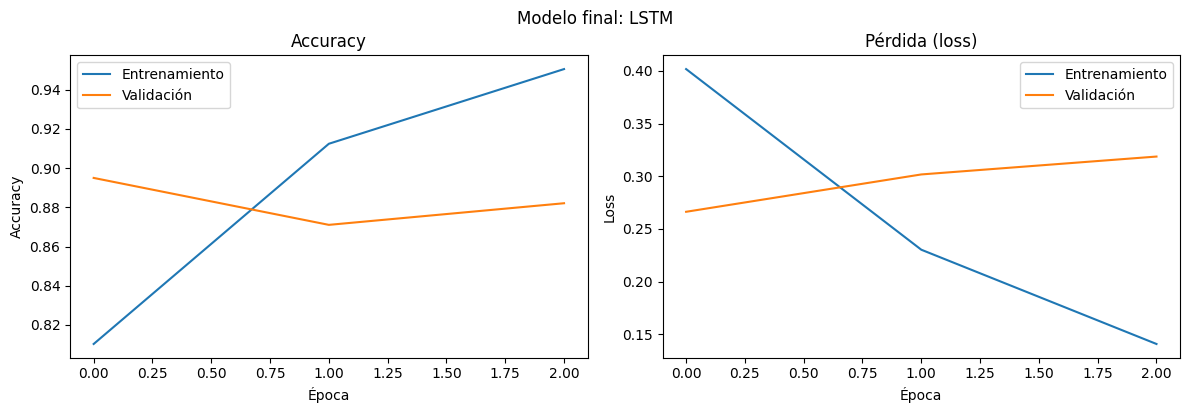

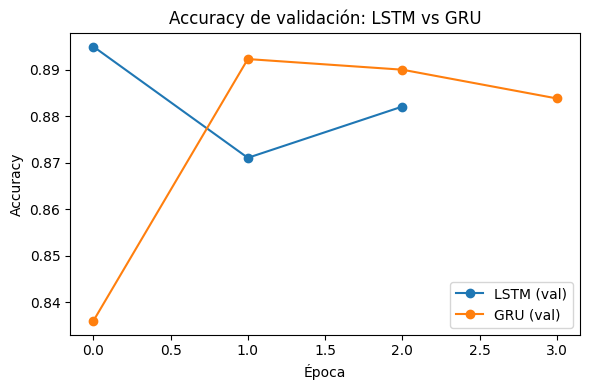

In [12]:
evaluate.plot_history(histories[best], "reports/training_curves.png")
plt.suptitle(f"Modelo final: {best.upper()}", y=1.02); plt.show()

# Comparación de ambas variantes
plt.figure(figsize=(6, 4))
for cell, h in histories.items():
    plt.plot(h.history["val_accuracy"], marker="o", label=f"{cell.upper()} (val)")
plt.title("Accuracy de validación: LSTM vs GRU"); plt.xlabel("Época"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout(); plt.savefig("reports/comparacion_lstm_gru.png", dpi=150); plt.show()

## 8. Evaluación en el conjunto de prueba

El dataset está balanceado, pero no basta el accuracy: se reportan también **precision, recall, F1 y ROC-AUC**, además de la **matriz de confusión** y la **curva ROC**.

In [13]:
y_true, probs, y_pred = evaluate.get_predictions(model, ds["test"])
metricas = evaluate.metrics_dict(y_true, probs, y_pred)
display(pd.Series(metricas, name="test").round(4).to_frame())
print(evaluate.text_report(y_true, y_pred))

,test
accuracy,0.8954
precision,0.8831
recall,0.9124
f1,0.8975
roc_auc,0.9582


              precision    recall  f1-score   support

    negativo      0.909     0.878     0.893      3705
    positivo      0.883     0.912     0.897      3733

    accuracy                          0.895      7438
   macro avg      0.896     0.895     0.895      7438
weighted avg      0.896     0.895     0.895      7438



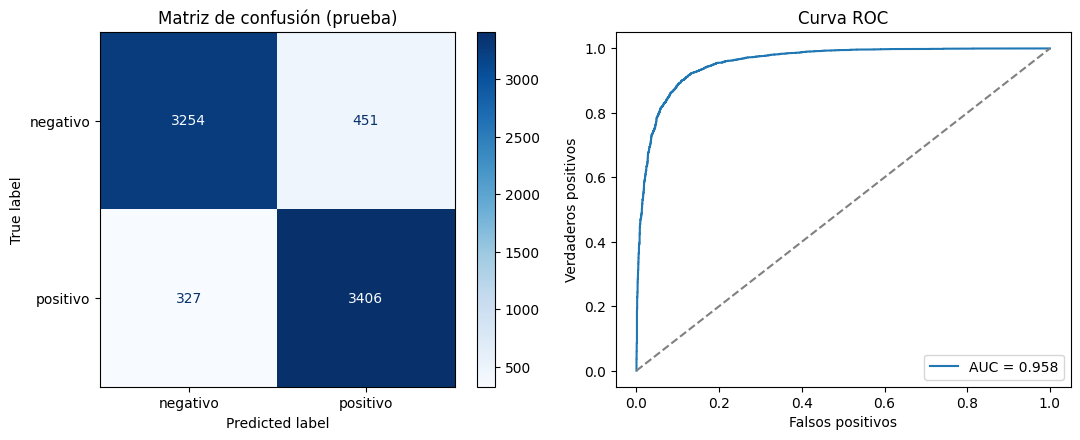

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, roc_auc_score
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=data.CLASS_NAMES).plot(ax=ax[0], cmap="Blues")
ax[0].set_title("Matriz de confusión (prueba)")
fpr, tpr, _ = roc_curve(y_true, probs)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, probs):.3f}"); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set(title="Curva ROC", xlabel="Falsos positivos", ylabel="Verdaderos positivos"); ax[1].legend()
plt.tight_layout(); plt.show()
evaluate.plot_confusion_matrix(y_true, y_pred, "reports/confusion_matrix.png"); plt.close()
evaluate.plot_roc(y_true, probs, "reports/roc_curve.png"); plt.close()

## 9. Predicciones de prueba (12 reseñas del conjunto de prueba)

In [15]:
tabla = evaluate.prediction_table(model, splits["test"], n=12)
pd.set_option("display.max_colwidth", 120)
display(tabla)
tabla.to_csv("reports/predictions.csv", index=False, encoding="utf-8")
print("Aciertos:", (tabla["acierto"] == "✅").sum(), "de", len(tabla))

,reseña,real,predicción,prob_positiva,confianza,acierto
0,"It is real easy to toast, roast, flay, and otherwise burn this film for all of its abundant flaws. It was made...",negativo,negativo,0.135,0.865,✅
1,This is really a great unknown movie.Perfect dialogue without the typical clichés.This movie relied on the act...,positivo,positivo,0.980,0.980,✅
2,"After reading previews for this movie I thought it would be a let down, however after I got my region 1 dvd ( ...",positivo,positivo,0.974,0.974,✅
3,"I saw this movie originally in the theater, when I was 10. Even at that age the 'humor' was mildly insulting t...",negativo,negativo,0.032,0.968,✅
4,"This was painful. I made myself watch it until the end, even though I had absolutely no interest in the plot, ...",negativo,negativo,0.023,0.977,✅
5,"After searching for 6 months, I finally found this DVD. All I can say is it was damn well worth the wait! ""Rus...",positivo,positivo,0.995,0.995,✅
6,"If you are a Crispin Glover fan, you must see this. If you are a Sean Penn fan, you must see this. If you are ...",positivo,positivo,0.656,0.656,✅
7,"With a title like that, you will be forgiven for thinking this film is about the great painter, Goya. Then aft...",negativo,negativo,0.108,0.892,✅
8,Diego Armando Maradona had been sixteen years of age in 1978 when Argentina won the World Cup at home. He was ...,positivo,positivo,0.933,0.933,✅
9,I can't remember many films where a bumbling idiot of a hero was so funny throughout. Leslie Cheung is such th...,positivo,positivo,0.951,0.951,✅


Aciertos: 11 de 12


In [16]:
# Errores más "seguros" del modelo (ayudan a entender sus límites)
test = splits["test"].copy()
test["prob"] = probs; test["pred"] = y_pred
mal = test[test.pred != test.label].copy()
mal["confianza"] = np.where(mal.pred == 1, mal.prob, 1 - mal.prob)
for _, r in mal.sort_values("confianza", ascending=False).head(4).iterrows():
    print(f"Real: {data.CLASS_NAMES[r.label]} | Pred: {data.CLASS_NAMES[r.pred]} ({r.confianza:.0%})")
    print("  ", r.text_clean[:250], "...\n")

Real: negativo | Pred: positivo (100%)
   this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the ...

Real: negativo | Pred: positivo (100%)
   This sleek, sexy movie is a must-see. Only upon multiple viewings can one truly understand the uniqueness of this film. Personally I enjoy the narrator for his intelligent, no subject left untouched, style of narration. The introduction grips you rig ...

Real: negativo | Pred: positivo (100%)
   I enjoyed the beautiful scenery in this movie the first time I saw it when I was 9 . Dunderklumpen is kind of cute for kiddies in a corny way. It reminded me of HRPUFFINSTUFF on sat mornings, Its Swedish backdrops make it easy on the eyes . Don't exp ...

Real: negativo | Pred: positivo (100%)
   I first saw the live musical at the Denver Center For The Perfor

In [17]:
# Prueba con frases nuevas (incluye casos difíciles: negación y sarcasmo)
from src.predict import predict_texts
frases = [
    "I loved every minute of this movie, a true masterpiece!",
    "Terrible acting and a boring script. Do not waste your money.",
    "It was not good at all.",
    "I expected much more, but it was fine I guess.",
    "Oh great, another two hours of my life I will never get back.",
]
for f, r in zip(frases, predict_texts(model, frases)):
    print(f"{r['label']:>8} ({r['confidence']:.0%}) <- {f}")

positivo (96%) <- I loved every minute of this movie, a true masterpiece!
negativo (100%) <- Terrible acting and a boring script. Do not waste your money.
positivo (63%) <- It was not good at all.
negativo (61%) <- I expected much more, but it was fine I guess.
positivo (61%) <- Oh great, another two hours of my life I will never get back.


## 10. Guardado del modelo

In [18]:
model.save("models/sentimiento_rnn.keras")
with open("reports/history.json", "w") as f:
    json.dump(histories[best].history, f)
with open("reports/metrics.json", "w") as f:
    json.dump({**metricas, "modelo": best}, f, indent=2)
with open("reports/classification_report.txt", "w", encoding="utf-8") as f:
    f.write(evaluate.text_report(y_true, y_pred))
comparacion.to_csv("reports/comparacion_modelos.csv")

# Comprobación: recargar y predecir como lo hará Streamlit
from src.predict import load_model, predict_text
m2 = load_model()
print(predict_text(m2, "A wonderful and moving film."))

{'label': 'positivo', 'confidence': 0.9436915516853333, 'prob_positive': 0.9436915516853333}


In [19]:
# En Colab: descarga los artefactos para subirlos al repositorio
if "google.colab" in sys.modules:
    !zip -r artefactos.zip models reports
    from google.colab import files
    files.download("artefactos.zip")

  adding: models/ (stored 0%)
  adding: models/sentimiento_rnn.keras (deflated 8%)
  adding: models/.gitkeep (stored 0%)
  adding: reports/ (stored 0%)
  adding: reports/roc_curve.png (deflated 11%)
  adding: reports/history.json (deflated 45%)
  adding: reports/comparacion_modelos.csv (deflated 19%)
  adding: reports/classification_report.txt (deflated 58%)
  adding: reports/confusion_matrix.png (deflated 15%)
  adding: reports/predictions.csv (deflated 50%)
  adding: reports/.gitkeep (stored 0%)
  adding: reports/metrics.json (deflated 28%)
  adding: reports/training_curves.png (deflated 10%)
  adding: reports/comparacion_lstm_gru.png (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>